In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("training_dataset_selected_features.csv")

In [3]:
df.head()

,MonthlyPersonalIncome,HighestEducation,AgeGroup,Q6_Transparency,Q8_Understanding,Q11_MaterialsAdequate,Q13_ViolenceCommon,Q14_OfficersInfluence,Q17_VoteForState,Q18_VoteForFriend,...,Q23_ReceivedGifts,Q25_PeopleSellVotes,Q28_VoteForFinancialAssistance,Q29_LackAccountabilityEncouragesVoteSelling,Q33_GiftsMoreLikelyWin,Q34_PeopleNoTrustElections,Zone_South South,EmploymentStatus_Part-time,EmploymentStatus_Retired,Target
0,0,2,1,2,2,2,3,2,3,4,...,0,3,5,2,3,3,0,0,0,0
1,3,2,4,1,2,3,3,2,3,3,...,0,2,4,3,2,2,0,0,0,0
2,3,0,2,1,1,2,2,3,2,2,...,0,2,2,3,3,4,0,0,0,1
3,0,5,1,2,3,4,2,3,2,1,...,0,2,4,3,2,3,0,0,0,0
4,2,1,0,2,2,2,2,2,2,2,...,0,3,3,5,2,3,0,0,0,0


In [4]:
df.shape

(444, 23)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 444 entries, 0 to 443
Data columns (total 23 columns):
 #   Column                                       Non-Null Count  Dtype
---  ------                                       --------------  -----
 0   MonthlyPersonalIncome                        444 non-null    int64
 1   HighestEducation                             444 non-null    int64
 2   AgeGroup                                     444 non-null    int64
 3   Q6_Transparency                              444 non-null    int64
 4   Q8_Understanding                             444 non-null    int64
 5   Q11_MaterialsAdequate                        444 non-null    int64
 6   Q13_ViolenceCommon                           444 non-null    int64
 7   Q14_OfficersInfluence                        444 non-null    int64
 8   Q17_VoteForState                             444 non-null    int64
 9   Q18_VoteForFriend                            444 non-null    int64
 10  Q19_Pressured             

In [6]:
df.describe()

,MonthlyPersonalIncome,HighestEducation,AgeGroup,Q6_Transparency,Q8_Understanding,Q11_MaterialsAdequate,Q13_ViolenceCommon,Q14_OfficersInfluence,Q17_VoteForState,Q18_VoteForFriend,...,Q23_ReceivedGifts,Q25_PeopleSellVotes,Q28_VoteForFinancialAssistance,Q29_LackAccountabilityEncouragesVoteSelling,Q33_GiftsMoreLikelyWin,Q34_PeopleNoTrustElections,Zone_South South,EmploymentStatus_Part-time,EmploymentStatus_Retired,Target
count,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,...,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000
mean,1.765766,2.844595,1.207207,1.369369,2.141892,3.027027,2.614865,2.853604,2.738739,2.662162,...,0.497748,2.646396,3.119369,3.380631,3.022523,3.610360,0.180180,0.049550,0.047297,0.421171
std,1.442377,1.388665,1.197191,0.580774,0.723767,0.949843,1.029083,0.951990,0.918451,0.947045,...,0.807691,0.862413,1.043818,0.894772,1.045008,0.878117,0.384771,0.217257,0.212513,0.739472
min,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2.000000,0.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,...,0.000000,2.000000,2.000000,3.000000,2.000000,3.000000,0.000000,0.000000,0.000000,0.000000
50%,2.000000,3.000000,1.000000,1.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,0.000000,3.000000,3.000000,3.000000,3.000000,4.000000,0.000000,0.000000,0.000000,0.000000
75%,3.000000,4.000000,2.000000,2.000000,3.000000,4.000000,3.000000,4.000000,3.000000,3.000000,...,1.000000,3.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000,0.000000,1.000000
max,5.000000,5.000000,4.000000,3.000000,4.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,2.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1.000000,1.000000,1.000000,2.000000


In [7]:
X = df.drop(columns =["Target"])
y = df["Target"]

In [8]:
selected_features = [
    "MonthlyPersonalIncome",
    "HighestEducation",
    "AgeGroup",
    "Q6_Transparency",
    "Q8_Understanding",
    "Q11_MaterialsAdequate",
    "Q13_ViolenceCommon",
    "Q14_OfficersInfluence",
    "Q17_VoteForState",
    "Q18_VoteForFriend",
    "Q19_Pressured",
    "Q21_GiftsShowCare",
    "Q22_ReceivingGiftsNormal",
    "Q23_ReceivedGifts",
    "Q25_PeopleSellVotes",
    "Q28_VoteForFinancialAssistance",
    "Q29_LackAccountabilityEncouragesVoteSelling",
    "Q33_GiftsMoreLikelyWin",
    "Q34_PeopleNoTrustElections",
    "Zone_South South",
    "EmploymentStatus_Part-time",
    "EmploymentStatus_Retired"
]

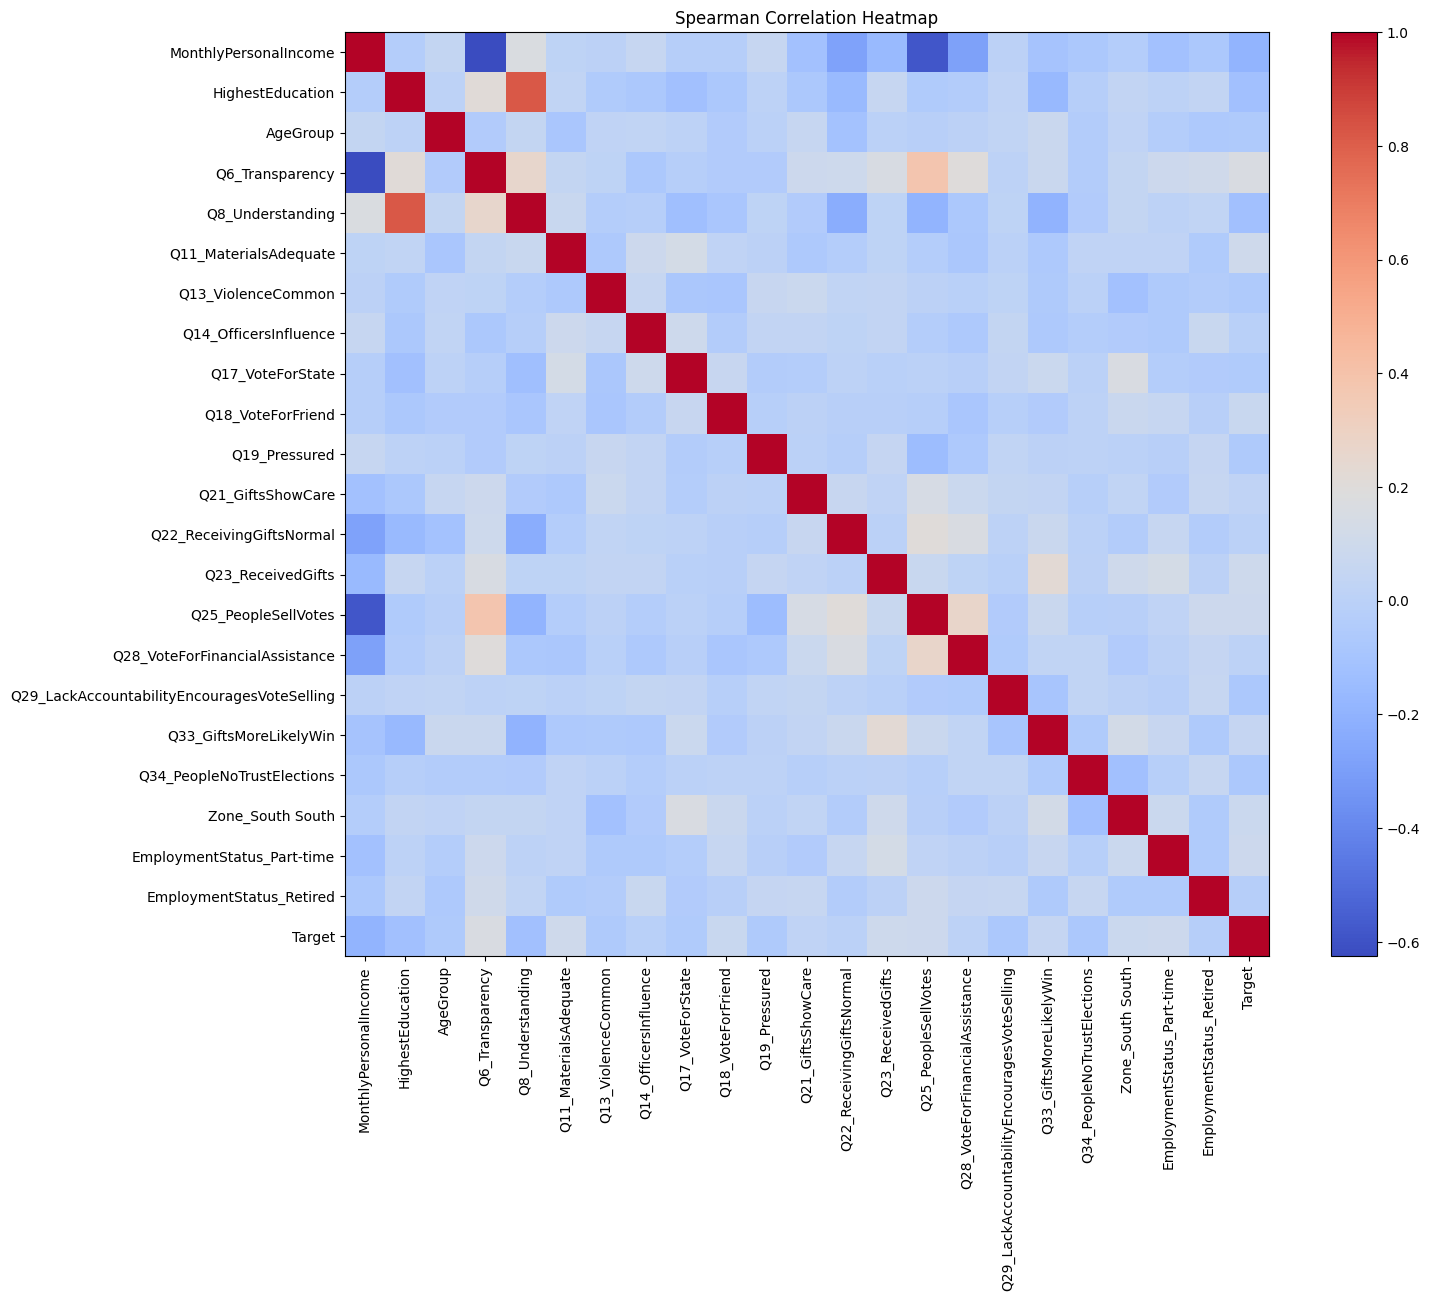

In [9]:
plt.figure(figsize=(16,12))
corr = df[selected_features + ["Target"]].corr(method='spearman')

plt.imshow(corr, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Spearman Correlation Heatmap")
plt.show()

In [ ]:
### split data to Train/Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [ ]:
###  RandomForest

In [11]:
rf = RandomForestClassifier(
    n_estimators=600,
    max_depth=12,
    class_weight="balanced",
    random_state=42
)

In [12]:
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [ ]:
### LightGBM

In [13]:
lgb = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=-1,
    objective="multiclass",
    num_class=3,
    random_state=42
)

In [14]:
lgb.fit(X_train, y_train)
lgb_pred = lgb.predict(X_test)


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000200 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 109
[LightGBM] [Info] Number of data points in the train set: 333, number of used features: 20
[LightGBM] [Info] Start training from score -0.315081
[LightGBM] [Info] Start training from score -2.119263
[LightGBM] [Info] Start training from score -1.896119
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further s

In [ ]:
### XGBoost

In [15]:
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42
)

In [16]:
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

In [ ]:
### Evaluation Function

In [17]:
def evaluate(model_name, y_true, y_pred):
    print(f"\n\n {model_name} Evaluation")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print(classification_report(y_true, y_pred))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()




 RandomForest Evaluation
Accuracy: 0.7207207207207207
              precision    recall  f1-score   support

           0       0.73      0.99      0.84        81
           1       0.00      0.00      0.00        13
           2       0.00      0.00      0.00        17

    accuracy                           0.72       111
   macro avg       0.24      0.33      0.28       111
weighted avg       0.53      0.72      0.61       111



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


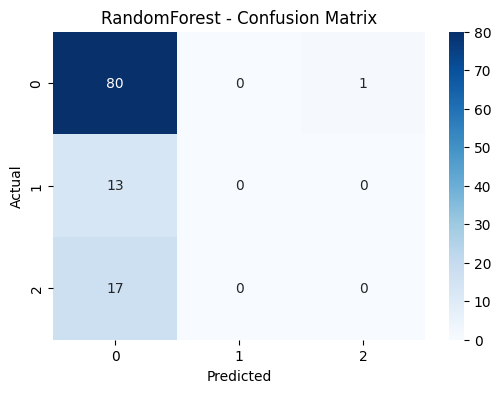

In [18]:
evaluate("RandomForest", y_test, rf_pred)



 LightGBM Evaluation
Accuracy: 0.7117117117117117
              precision    recall  f1-score   support

           0       0.77      0.90      0.83        81
           1       0.43      0.23      0.30        13
           2       0.33      0.18      0.23        17

    accuracy                           0.71       111
   macro avg       0.51      0.44      0.45       111
weighted avg       0.66      0.71      0.68       111



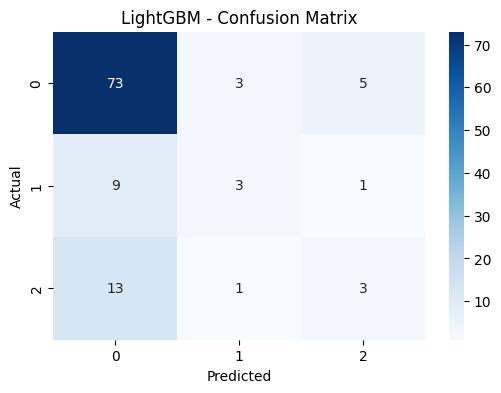

In [19]:
evaluate("LightGBM", y_test, lgb_pred)



 XGBoost Evaluation
Accuracy: 0.7117117117117117
              precision    recall  f1-score   support

           0       0.73      0.95      0.83        81
           1       0.50      0.08      0.13        13
           2       0.25      0.06      0.10        17

    accuracy                           0.71       111
   macro avg       0.49      0.36      0.35       111
weighted avg       0.63      0.71      0.63       111



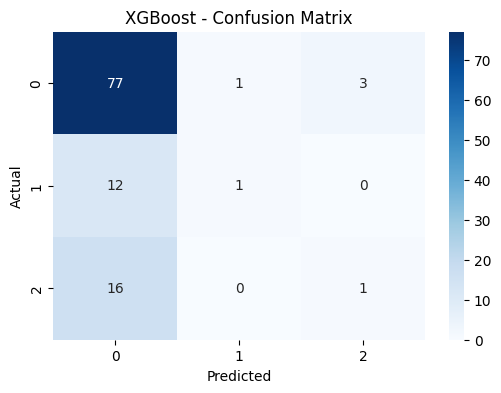

In [20]:
evaluate("XGBoost", y_test, xgb_pred)

### HYPERPARAMETER TUNING
Cross-validation with stratification, Optimized hyperparameters for all 3 models

In [21]:
# Stratified K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Hyperparameter Tuning for RandomForest

In [22]:
rf_model = RandomForestClassifier(random_state=42)

In [23]:
rf_param_grid = {
    "n_estimators": [200, 400, 600, 800],
    "max_depth": [6, 10, 15, 20, None],
    "min_samples_split": [2, 4, 6],
    "min_samples_leaf": [1, 2, 4],
    "bootstrap": [True, False],
    "class_weight": ["balanced", "balanced_subsample", None]
}

In [24]:
rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_param_grid,
    n_iter=40,
    cv=skf,
    scoring="accuracy",
    verbose=1,
    n_jobs=-1,
    random_state=42
)

rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_
print("Best RandomForest params:", rf_search.best_params_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best RandomForest params: {'n_estimators': 800, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 10, 'class_weight': None, 'bootstrap': True}


### Hyperparameter Tuning for tje LightGBM

In [25]:
lgb_model = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    random_state=42
)

In [26]:
lgb_param_grid = {
    "n_estimators": [200, 400, 600, 800],
    "learning_rate": [0.005, 0.01, 0.05, 0.1],
    "max_depth": [-1, 4, 6, 8, 10],
    "num_leaves": [15, 31, 50, 70],
    "min_child_samples": [10, 20, 30],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0]
}

In [27]:
lgb_search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=lgb_param_grid,
    n_iter=40,
    cv=skf,
    scoring="accuracy",
    verbose=1,
    n_jobs=-1,
    random_state=42
)

lgb_search.fit(X_train, y_train)
lgb_best = lgb_search.best_estimator_
print("Best LightGBM params:", lgb_search.best_params_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000052 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 109
[LightGBM] [Info] Number of data points in the train set: 333, number of used features: 20
[LightGBM] [Info] Start training from score -0.315081
[LightGBM] [Info] Start training from score -2.119263
[LightGBM] [Info] Start training from score -1.896119
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

### Hyperparameter Tuning for XGBoost

In [28]:
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42
)

In [29]:
xgb_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 7]
}

In [30]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_param_grid,
    n_iter=40,
    cv=skf,
    scoring="accuracy",
    verbose=1,
    n_jobs=-1,
    random_state=42
)

xgb_search.fit(X_train, y_train)
xgb_best = xgb_search.best_estimator_
print("Best XGBoost params:", xgb_search.best_params_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best XGBoost params: {'subsample': 0.8, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.6}


In [ ]:
### Evaluation of finetuend Models

In [32]:
models = {
    "RandomForest": rf_best,
    "LightGBM": lgb_best,
    "XGBoost": xgb_best
}



 Evaluating: RandomForest
Accuracy: 0.7297297297297297
              precision    recall  f1-score   support

           0       0.73      1.00      0.84        81
           1       0.00      0.00      0.00        13
           2       0.00      0.00      0.00        17

    accuracy                           0.73       111
   macro avg       0.24      0.33      0.28       111
weighted avg       0.53      0.73      0.62       111



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


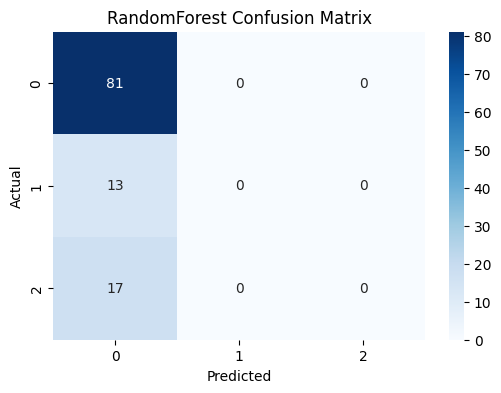



 Evaluating: LightGBM
Accuracy: 0.7297297297297297
              precision    recall  f1-score   support

           0       0.73      1.00      0.84        81
           1       0.00      0.00      0.00        13
           2       0.00      0.00      0.00        17

    accuracy                           0.73       111
   macro avg       0.24      0.33      0.28       111
weighted avg       0.53      0.73      0.62       111



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


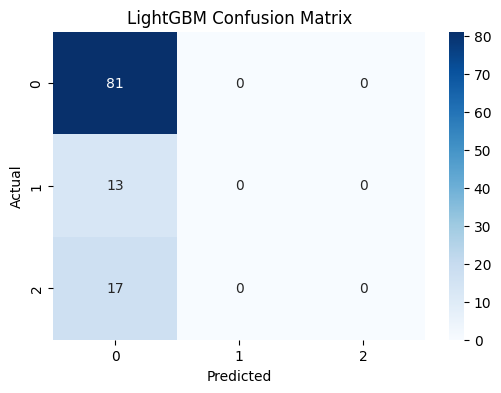



 Evaluating: XGBoost
Accuracy: 0.7297297297297297
              precision    recall  f1-score   support

           0       0.73      1.00      0.84        81
           1       0.00      0.00      0.00        13
           2       0.00      0.00      0.00        17

    accuracy                           0.73       111
   macro avg       0.24      0.33      0.28       111
weighted avg       0.53      0.73      0.62       111



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


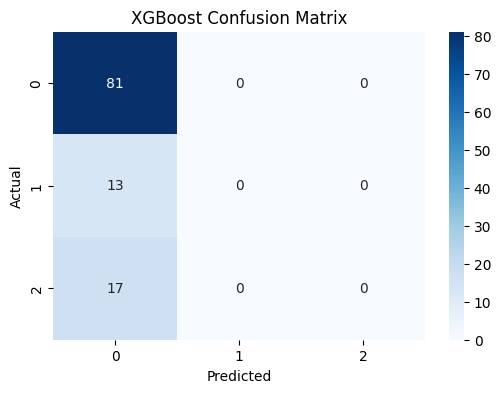

In [33]:
for name, model in models.items():
    print("\n\n Evaluating:", name)

    preds = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, preds))
    print(classification_report(y_test, preds))

    cm = confusion_matrix(y_test, preds)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


In [34]:
import joblib

In [35]:
# collect model scores
model_scores = {
    "XGBoost": accuracy_score(y_test, xgb_best.predict(X_test)),
    "LightGBM": accuracy_score(y_test, lgb_best.predict(X_test)),
    "RandomForest": accuracy_score(y_test, rf_best.predict(X_test))
}

In [36]:
best_model_name = max(model_scores, key=model_scores.get)
best_model = {
    "XGBoost": xgb_best,
    "LightGBM": lgb_best,
    "RandomForest": rf_best
}[best_model_name]

print("Best Model:", best_model_name)

Best Model: XGBoost


In [37]:
joblib.dump(best_model, f"{best_model_name}_best_model.joblib")

['XGBoost_best_model.joblib']